Tips Dataset: Clear and Honest Data Visualisation
Project goal: Explore a real restaurant tips dataset and communicate patterns with clear charts.
Four questions
1. How are restaurant bills distributed?
2. Do bills differ across days?
3. Is a larger bill associated with a larger tip?
4. Which numerical variables move together most strongly?
Dataset
We use Seaborn's built-in tips dataset. Each row represents one restaurant bill and includes the total bill, tip, day, time, party size, and smoker status.

1. Import libraries and load the dataset
Run this notebook in VS Code with the Jupyter extension and a Python kernel. The first load may need an internet connection because Seaborn downloads its sample dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create a folder for all saved chart images
output_dir = Path("charts")
output_dir.mkdir(exist_ok=True)

# A built-in real-world sample dataset from Seaborn
df = sns.load_dataset("tips")

# Consistent, readable styling and colour palette
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


2. Inspect the data
Check the column names, data types, missing values and summary statistics before plotting.

In [2]:
print("Dataset information:")
df.info()

print("\\nMissing values:")
display(df.isna().sum())

print("\\nSummary statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
\nMissing values:


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_bill,244.0,NaN,NaN,NaN,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,NaN,NaN,NaN,2.998279,1.383638,1.0,2.0,2.9,3.5625,10.0
sex,244,2,Male,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoker,244,2,No,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,244,4,Sat,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,244,2,Dinner,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
size,244.0,NaN,NaN,NaN,2.569672,0.9511,1.0,2.0,2.0,3.0,6.0


3. Histogram — How are restaurant bills distributed?
A histogram shows how often values fall into different ranges. The x-axis is the bill amount in dollars; the y-axis is the number of bills.

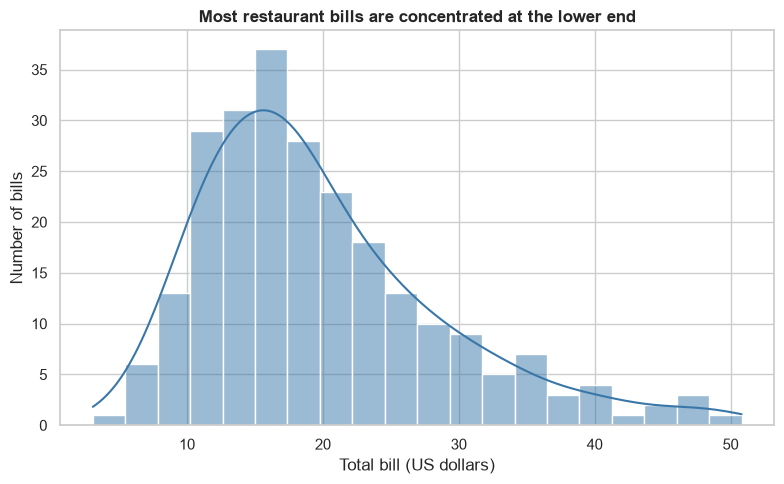

Takeaway: The median bill is $17.80; the histogram shows how bill amounts are distributed.


In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="total_bill", bins=20, kde=True, color="#3977A8")
plt.title("Most restaurant bills are concentrated at the lower end", weight="bold")
plt.xlabel("Total bill (US dollars)")
plt.ylabel("Number of bills")
plt.tight_layout()
plt.savefig(output_dir / "01_bill_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

median_bill = df["total_bill"].median()
print(f"Takeaway: The median bill is ${median_bill:.2f}; the histogram shows how bill amounts are distributed.")

4. Box plot — Do bills differ across days?
A box plot compares the middle value and spread of bills across days. Dots beyond the whiskers may be unusually high or low observations; they are not automatically errors.

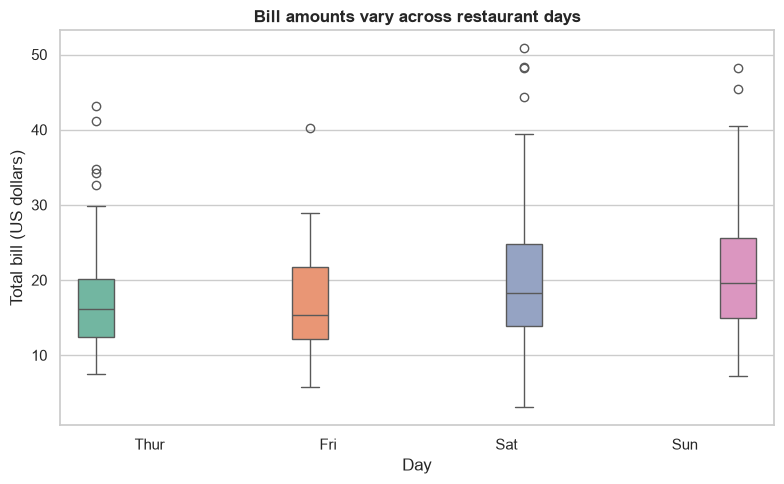

Median bill by day:


day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64

Takeaway: The median bill is highest on Sun ($19.63) and lowest on Fri ($15.38).


In [4]:
day_order = ["Thur", "Fri", "Sat", "Sun"]
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="day", y="total_bill", order=day_order,
            hue="day", palette="Set2", legend=False)
plt.title("Bill amounts vary across restaurant days", weight="bold")
plt.xlabel("Day")
plt.ylabel("Total bill (US dollars)")
plt.tight_layout()
plt.savefig(output_dir / "02_bill_boxplot_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

day_medians = df.groupby("day", observed=False)["total_bill"].median().reindex(day_order)
print("Median bill by day:")
display(day_medians.round(2))
print(f"Takeaway: The median bill is highest on {day_medians.idxmax()} (${day_medians.max():.2f}) and lowest on {day_medians.idxmin()} (${day_medians.min():.2f}).")

5. Scatter plot — Is a larger bill associated with a larger tip?
Each dot represents one bill. The trend line summarises the overall relationship; it does not mean that bill size alone causes a particular tip.

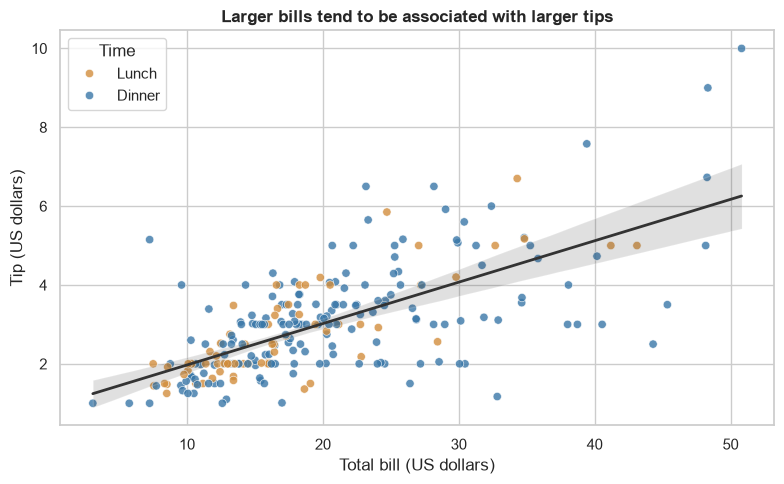

Takeaway: Total bill and tip have a positive correlation of 0.68, meaning larger bills tend to accompany larger tips.


In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time",
                palette={"Lunch": "#D28E3D", "Dinner": "#3977A8"},
                alpha=0.8)
sns.regplot(data=df, x="total_bill", y="tip", scatter=False,
            color="#333333", line_kws={"linewidth": 2})
plt.title("Larger bills tend to be associated with larger tips", weight="bold")
plt.xlabel("Total bill (US dollars)")
plt.ylabel("Tip (US dollars)")
plt.legend(title="Time")
plt.tight_layout()
plt.savefig(output_dir / "03_bill_vs_tip_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

bill_tip_corr = df["total_bill"].corr(df["tip"])
print(f"Takeaway: Total bill and tip have a positive correlation of {bill_tip_corr:.2f}, meaning larger bills tend to accompany larger tips.")

6. Bar chart — What is the average bill by day?
A bar chart compares one summary value (here, the mean bill) across categories. The vertical axis starts at zero so the bar heights are not visually exaggerated.

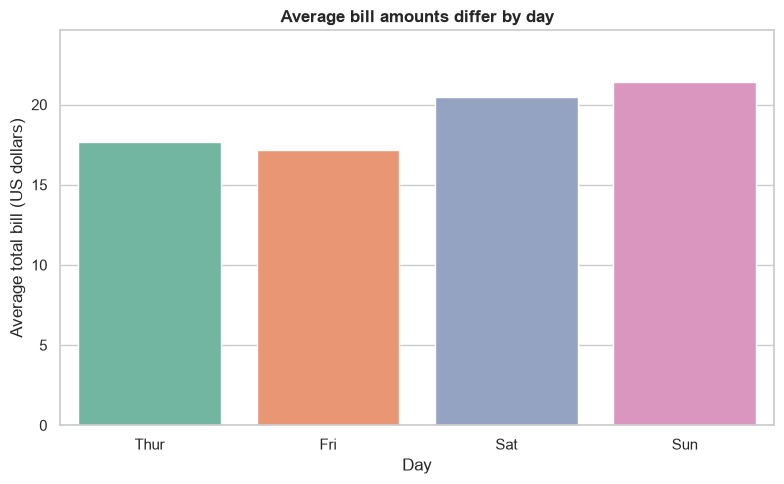

Average bill by day:


day
Thur    17.68
Fri     17.15
Sat     20.44
Sun     21.41
Name: total_bill, dtype: float64

Takeaway: Sun has the highest average bill ($21.41) in this dataset.


In [6]:
mean_bill_by_day = df.groupby("day", observed=False)["total_bill"].mean().reindex(day_order)

plt.figure(figsize=(8, 5))
sns.barplot(x=mean_bill_by_day.index, y=mean_bill_by_day.values,
            hue=mean_bill_by_day.index, palette="Set2", legend=False)
plt.title("Average bill amounts differ by day", weight="bold")
plt.xlabel("Day")
plt.ylabel("Average total bill (US dollars)")
plt.ylim(0, mean_bill_by_day.max() * 1.15)
plt.tight_layout()
plt.savefig(output_dir / "04_average_bill_bar_chart.png", dpi=150, bbox_inches="tight")
plt.show()

print("Average bill by day:")
display(mean_bill_by_day.round(2))
print(f"Takeaway: {mean_bill_by_day.idxmax()} has the highest average bill (${mean_bill_by_day.max():.2f}) in this dataset.")

7. Correlation heatmap — Which numerical variables move together?
Correlation values range from -1 to +1:
- Close to +1: strong positive relationship.
- Close to -1: strong negative relationship.
- Close to 0: weak linear relationship.
Correlation does not prove cause and effect.

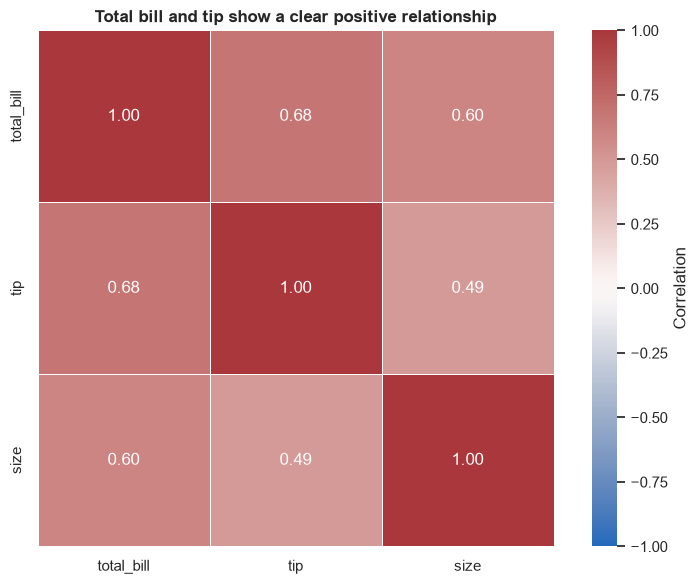

Takeaway: The strongest numerical relationship is between total_bill and tip (correlation = 0.68).


In [7]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Total bill and tip show a clear positive relationship", weight="bold")
plt.tight_layout()
plt.savefig(output_dir / "05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Find the strongest pair excluding the diagonal self-correlations
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strongest_pair = upper.abs().stack().idxmax()
strongest_value = corr.loc[strongest_pair[0], strongest_pair[1]]
print(f"Takeaway: The strongest numerical relationship is between {strongest_pair[0]} and {strongest_pair[1]} (correlation = {strongest_value:.2f}).")

8. Save a four-chart dashboard image
This 2-by-2 dashboard combines the histogram, box plot, scatter plot and correlation heatmap. A separate bar chart is also saved above.

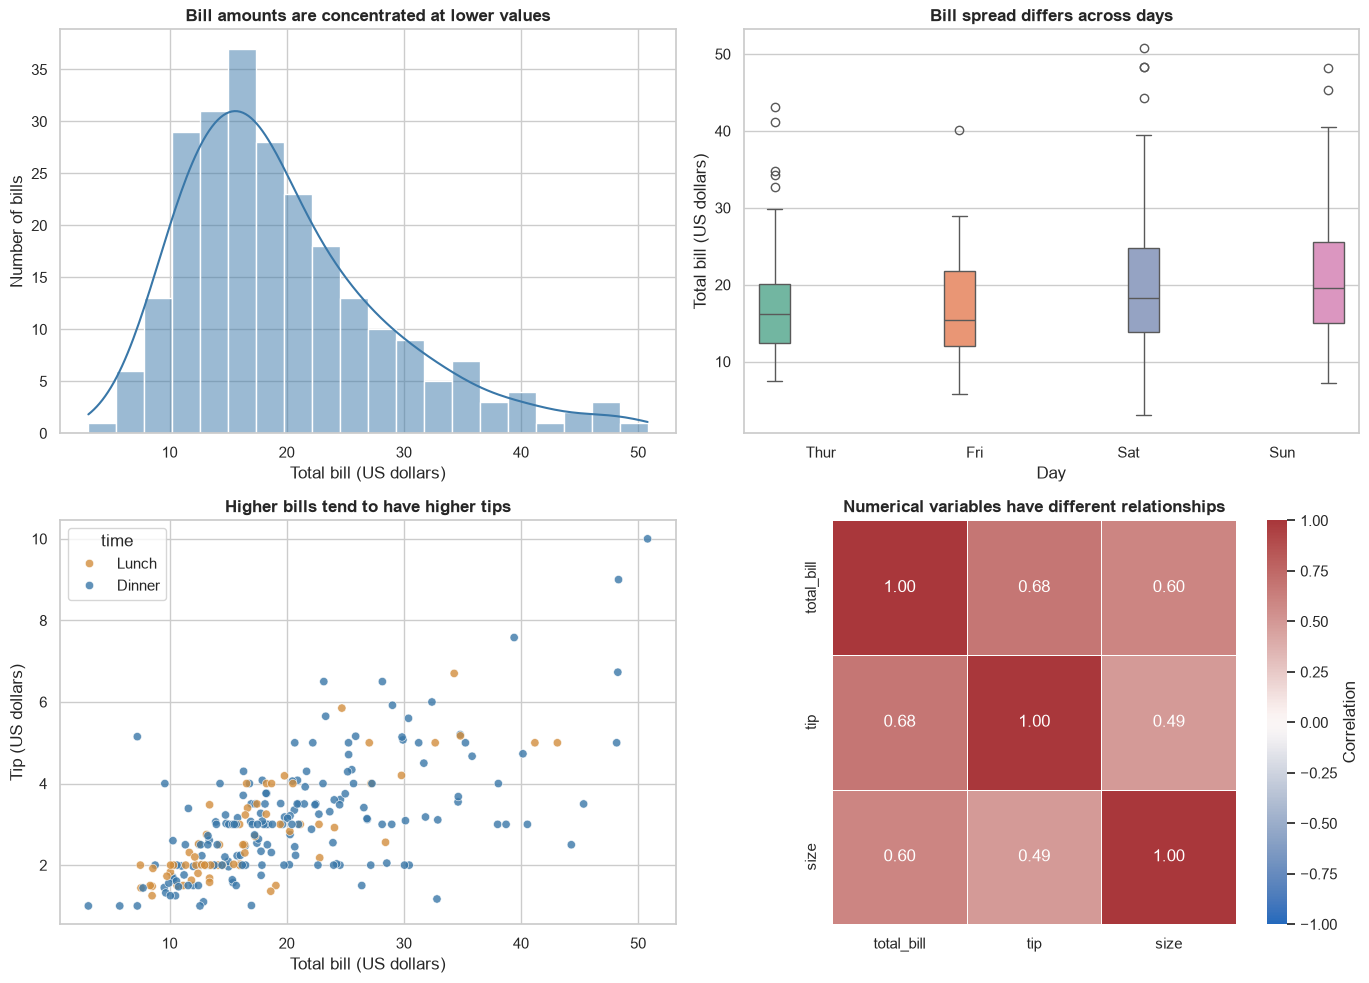

Dashboard saved to: C:\Users\Lenovo\OneDrive\Desktop\Interncircle\charts\06_tips_dashboard.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=df, x="total_bill", bins=20, kde=True, color="#3977A8", ax=axes[0, 0])
axes[0, 0].set_title("Bill amounts are concentrated at lower values", weight="bold")
axes[0, 0].set_xlabel("Total bill (US dollars)")
axes[0, 0].set_ylabel("Number of bills")

sns.boxplot(data=df, x="day", y="total_bill", order=day_order,
            hue="day", palette="Set2", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Bill spread differs across days", weight="bold")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Total bill (US dollars)")

sns.scatterplot(data=df, x="total_bill", y="tip", hue="time",
                palette={"Lunch": "#D28E3D", "Dinner": "#3977A8"},
                alpha=0.8, ax=axes[1, 0])
axes[1, 0].set_title("Higher bills tend to have higher tips", weight="bold")
axes[1, 0].set_xlabel("Total bill (US dollars)")
axes[1, 0].set_ylabel("Tip (US dollars)")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[1, 1],
            cbar_kws={"label": "Correlation"})
axes[1, 1].set_title("Numerical variables have different relationships", weight="bold")

plt.tight_layout()
dashboard_path = output_dir / "06_tips_dashboard.png"
plt.savefig(dashboard_path, dpi=150, bbox_inches="tight")
plt.show()

print("Dashboard saved to:", dashboard_path.resolve())

9. Written takeaways
The chart cells above print numerical takeaways based on the dataset. Summarise them in your submission using the values shown after running the notebook:
1. Histogram: Describe where most bill amounts fall and report the median bill.
2. Box plot: Compare median bills across days and mention the highest and lowest.
3. Scatter plot: State whether bill and tip have a positive or negative relationship and report the correlation.
4. Bar chart: Identify the day with the highest average bill.
5. Heatmap: Identify the strongest numerical relationship and report its correlation value.

## Conclusion

In this project, data visualisation was performed using Python, Pandas, Matplotlib, and Seaborn on the Tips dataset. Different charts, including histograms, box plots, scatter plots, bar charts, and correlation heatmaps, were created to understand the data.

The analysis helped identify the distribution of restaurant bills, differences in bills across days, and the relationship between total bills and tips. The correlation heatmap provided a clear view of relationships between numerical variables.

Overall, this project improved my understanding of data visualisation, chart selection, colour palettes, and presenting data through meaningful insights. It also showed how charts can make complex data easier to understand and interpret.